# PSA のエネルギーの較正: ピクセルごとの p0, p1(`energy_haNN.csv`)

`PSA_Calibration` は、ピクセルごとの係数で **`energy = p0 + p1 × hg_corr`** [keV] にします(`hg_corr` は温度で直した hg)。
係数の表 `calib/psa/energy_haNN.csv`(`ch,n,m,p0,p1`)を、エネルギーの分かった線源のランから作るのが `scripts/calib/make_psa_energy.py` です。

| 手順 | 中身 |
|---|---|
| 0. 準備 | 位置(`position_haNN.csv`)と温度ゲイン(`temp_gain_haNN.csv`)を `calib/psa` に置いた状態で、線源のランをチェーンに通す(ピクセルと `hg_corr` が要る) |
| 1. ヒットを選ぶ | ピクセルがあり、飽和していなく、ピークがトリガーの時刻のもの |
| 2. 線の位置 | ピクセルごとの `hg_corr` のスペクトルで、`--line E` なら光電ピーク(温度ゲインと同じ探し方)、`--line E:lo:hi` なら lo〜hi の中の最大 |
| 3. 係数 | 線 1 本: `p0 = 0`, `p1 = E / 位置`。2 本以上: 直線 `E = p0 + p1 × 位置` を最小二乗で |
| 4. 統計の少ないピクセル | ヒットが 500(`--min-hits`)未満のピクセルは、その ch の和のスペクトルを使う(`src` 列が `ch`) |

ここでは **Cs-137 の 662 keV の光電ピーク**(run01〜11)で、線 1 本の較正を作ります。
Co(run12)の約 5 万の山は、光電ピークかコンプトン端かがまだ分かっていないので使いません(Notion)。
線 1 本なので `p0 = 0` で、hg_corr と エネルギーが比例すると仮定しています。直線性を確かめるには、別の線(エネルギーの違う線源)が要ります。

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import Image, display
import ROOT
ROOT.gROOT.SetBatch(True)

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
CALIB_SCRIPTS = REPO / "scripts" / "calib"
sys.path.insert(0, str(CALIB_SCRIPTS))
CACHE = REPO / "tutorials" / "cache"      # チェーンの出力の置き場(git には入れない)
CACHE.mkdir(exist_ok=True)
CAL_OUT = CACHE / "calib_psa"              # このノートブックで作る較正ファイル(calib/psa は上書きしない)
CAL_OUT.mkdir(exist_ok=True)
PYTHON = "/usr/bin/python3"                # scripts/calib を動かす Python(numpy, scipy, PyROOT)
DATA = Path(os.environ.get("SMILE3_PSA_CAL_DATA", "/mnt/d/UVSOR2026_late"))

def run(cmd, show=True):
    """コマンドを実行し、出力を表示する"""
    print(" ".join(str(c) for c in cmd))
    r = subprocess.run([str(c) for c in cmd], capture_output=True, text=True)
    if show:
        print(r.stdout[-4000:])
    if r.returncode != 0:
        print(r.stderr[-4000:])
    r.check_returncode()

def chain(run_name, out, *args):
    """UVSOR のラン 1 本を smile3_psa で流す(出力が既にあれば何もしない)"""
    if out.exists():
        return out
    run([sys.executable, RUN_CHAIN, "smile3_psa", "-o", out, "--data-dir", DATA / "killua" / run_name,
         "--set", "PSA_ReadData.extra_data_dirs=" + json.dumps([str(DATA / "calltt" / run_name)]), *args], show=False)
    return out

## 1. データ

2026-11-03 の UVSOR での HA_cal のランを使います(解析用の計算機の D ドライブ `/mnt/d/UVSOR2026_late`。
ほかの場所にあるときは環境変数 `SMILE3_PSA_CAL_DATA`)。ランの記録は Notion の
「SMILE-3 FM UVSOR 試験(2026-11-03)データ確認と HA_cal の解析」にあります。

| ラン | 線源 | 温度 | 中身 |
|---|---|---|---|
| run01〜11 | Cs-137 | 39〜49 °C | 1 ランは約 2 分。多くは storage の OOM で途中で止まった(.dat.tmp が残る) |
| run12 | Co | 47〜49 °C | 4 時間。ha02 で 1 ch あたり 130〜160 万ヒット。ほぼ全部がトリガーの時刻に入る。ha04 は無い |

チェーンの出力は 1 ランに 1 つ、`tutorials/cache/psa_<ラン>.root` に置き、既にあれば流し直しません
(Cs は 1 ランに 1〜4 分、run12 は約 2 時間)。

## 2. 位置と温度ゲインを置いた状態で Cs のランを流す

`calib/psa` の位置と温度ゲインを使って流した出力は、`psa_cal_<ラン>.root` という名前にします(温度ゲインの表を作るのに使った `psa_<ラン>.root` とは別)。

In [2]:
print("calib/psa:", sorted(p.name for p in (REPO / "calib" / "psa").glob("temp_gain_ha*.csv"))[:3], "...")
RUNS = [f"20261103_run{k:02d}" for k in range(1, 12)]
ROOTS = [chain(r, CACHE / f"psa_cal_{r}.root") for r in RUNS]
print(len(ROOTS), "files")

calib/psa: ['temp_gain_ha00.csv', 'temp_gain_ha01.csv', 'temp_gain_ha02.csv'] ...
11 files


## 3. 係数を作る

ha02 を作ります(全ボードなら `--boards` を外す)。

In [3]:
run([PYTHON, CALIB_SCRIPTS / "make_psa_energy.py", *ROOTS, "-o", CAL_OUT, "--boards", "2", "--line", "662", "--overwrite"])
print("".join(l for l in open(CAL_OUT / "energy_ha02.csv").readlines()[:20] if not l.startswith("# input")))

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/scripts/calib/make_psa_energy.py /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run01.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run02.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run03.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run04.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run05.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run06.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run07.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run08.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run09.root /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/psa_cal_20261103_run10.root /home/onoda/ANLNext/Erica_

ha02: /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/calib_psa/energy_ha02.csv (384 pixels, 0 from the ch sum)

# made by scripts/calib/make_psa_energy.py, 2026-11-05T18:44:18
# hits: !satu_h && !satu_l && pixel >= 0 && (board == 2), peak_id 27-29; spectra of hg_corr (250 bins up to 100000)
# lines: 662 keV (photopeak above 15000)
# pixels with < 500 hits use the sum of the ch: 0
ch,n,m,p0,p1,src,hits,pos_1
0,1,1,0,0.0238129,pixel,3385,27800
0,1,2,0,0.021634,pixel,4660,30600
0,1,3,0,0.022517,pixel,4817,29400
0,1,4,0,0.0245185,pixel,4310,27000



## 4. 確認

`qa/energy_ha02.png` はピクセルごとの `p1` [keV / hg_corr] です。隣のピクセルと大きく違う所は、線の位置を取り違えている可能性があります。

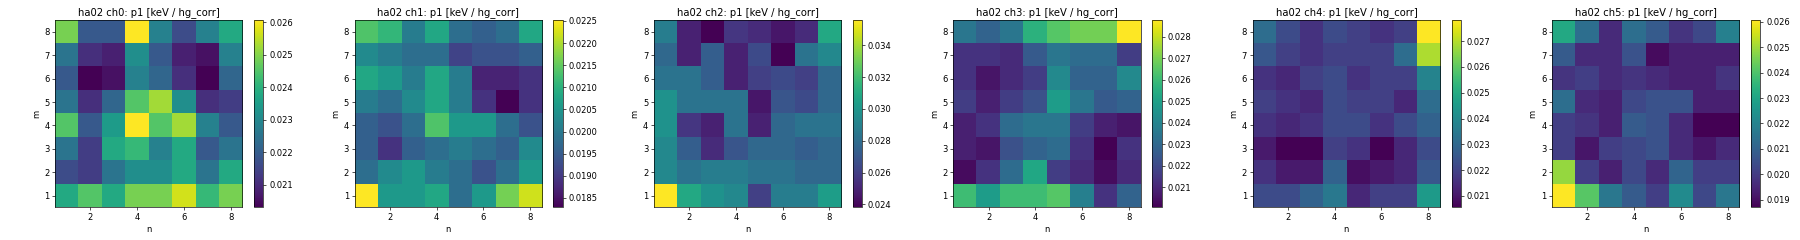

In [4]:
display(Image(filename=str(CAL_OUT / "qa" / "energy_ha02.png")))

作った係数で、ピクセルごとにエネルギーに直したスペクトルを、ch ごとに足して描きます。662 keV にそろえば、ピクセルごとのゲインの違いが直っています。

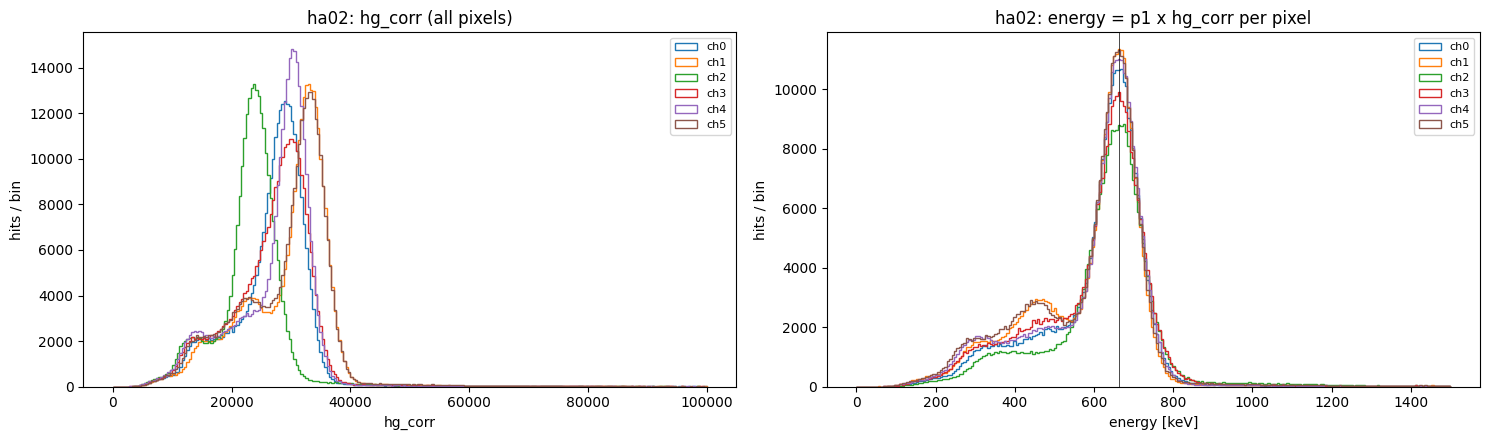

In [5]:
import csv
from psa_calib_common import read_tree
rows = list(csv.DictReader(l for l in open(CAL_OUT / "energy_ha02.csv") if not l.startswith("#")))
p1 = {(int(r["ch"]), int(r["n"]), int(r["m"])): float(r["p1"]) for r in rows}
d = read_tree([str(r) for r in ROOTS], ["ch", "pix_n", "pix_m", "hg_corr"],
              "board == 2 && pixel >= 0 && !satu_h && !satu_l && peak_id >= 26 && peak_id <= 29")
k = np.array([p1.get((c, n, m), np.nan) for c, n, m in zip(d["ch"], d["pix_n"], d["pix_m"])])
e = k * d["hg_corr"]
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for c in range(6):
    s = d["ch"] == c
    axs[0].hist(d["hg_corr"][s], bins=250, range=(0, 1e5), histtype="step", label=f"ch{c}")
    axs[1].hist(e[s], bins=250, range=(0, 1500), histtype="step", label=f"ch{c}")
axs[0].set_xlabel("hg_corr"); axs[1].set_xlabel("energy [keV]"); axs[1].axvline(662, color="k", lw=0.5)
for a in axs:
    a.set_ylabel("hits / bin"); a.legend(fontsize=8)
axs[0].set_title("ha02: hg_corr (all pixels)"); axs[1].set_title("ha02: energy = p1 x hg_corr per pixel")
fig.tight_layout(); plt.show()

## 5. 使う

確認して使えると判断したら、`calib/psa/` に書きます。次にチェーンを流すと、`energy` と `PSA_Calibration/Energy_haNN` が入ります。

```bash
/usr/bin/python3 scripts/calib/make_psa_energy.py tutorials/cache/psa_cal_20261103_run{01..11}.root -o calib/psa --line 662 --overwrite
```